Machine Learning for Next-Day Rain Prediction in Lund: From Weather Pattern Clustering to Model Comparison

1. Data Preprocessing and Exploration
在数据预处理与探索阶段，我们需要加载隆德气象数据集 lund_daily_weather.csv 并检查数据结构，利用描述性统计（Descriptive Statistics）计算气温、气压和湿度等特征的基础统计量，通过绘制直方图（Histograms）展示最高温、露点差与气压波动等特征的分布，利用散点图（Scatter Plots）分析气压与湿度的关联，同时利用 shift(-1) 错开一天构建次日降雨目标变量（Target Alignment），并采用四分位距（IQR）或箱线图等过滤条件识别和剔除异常天气数据（Outliers）。
2. Unsupervised Learning – Clustering
在无监督学习与聚类阶段，我们需要挑选露点差、昼夜温差和气压变幅等核心气象特征（Feature Selection），使用 K-Means 算法将每日天气无监督聚类为不同的天气模式（Weather Patterns，如晴朗干燥型、阴湿高压型与低压风暴型），应使用轮廓系数等聚类指标，并检查各个簇的气象特征。
3. Supervised Learning – Classification
在监督学习与分类阶段，我们需要以构建好的次日降雨标签 RainTomorrow 为目标，将较早日期用于训练、之后的数据用于验证和测试，训练决策树（Decision Tree）和随机森林（Random Forest）作为基准分类模型，利用准确率（Accuracy）、精确率（Precision）、召回率（Recall）、F1-score 以及混淆矩阵（Confusion Matrix）评估模型性能，并通过对物理特征参数进行极值与均值拟合缩放（Optimal Parameter Scaling），深入分析传统模型在气象预测中的优缺点与瓶颈。
4. Neural Network Implementation
在神经网络实现阶段，我们需要使用 PyTorch 搭建随机森林模型的，引入 Dropout 层与早停法（Early Stopping）等正则化技术防止过拟合，以交叉熵损失驱动训练并提取高阶特征组合，随后在测试集上使用与监督学习相同的评估指标（Accuracy, F1-score, Confusion Matrix）衡量性能。
5. Data Visualization and Presentation
在数据可视化与结果汇报阶段，我们需要绘制神经网络在各个训练轮次（Epochs）中的训练与验证损失曲线（Loss Curves）及准确率变化曲线（Accuracy Curves）以验证收敛性，同时创建特征重要性条形图（Feature Importance）与 ROC-AUC 曲线等可视化图表突出核心洞察，最终将完整的数据管线（Data Pipeline）、模型对比结果、代码片段与物理解释整合为一份结构清晰、逻辑完备的终极汇报报告（Final Presentation & Report）。

In [1]:
#Before this, first run 'get_data' to fetch training data named 'lund_daily_weather'.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.ensemble import RandomForestClassifier



In [3]:
# Set plotting style
sns.set_theme(style="whitegrid")
# ==============================================================================
# 1.1 Data Loading & Basic Exploration
# ==============================================================================
# Load the dataset
df_daily = pd.read_csv("lund_daily_weather.csv")

print("Dataset Shape:", df_daily.shape)
print("\n--- First 5 rows ---")
display(df_daily.head())

print("\n--- Data Types and Missing Values ---")
df_daily.info()

Dataset Shape: (5478, 15)

--- First 5 rows ---


,date,temp_max,temp_min,temp_mean,humidity_mean,dewpoint_mean,pressure_mean,cloud_cover_mean,wind_speed_max,precipitation_today,temp_range,dewpoint_spread,pressure_change,month,rain_tomorrow
0,2010-01-01,-4.7,-8.3,-6.741667,80.208333,-9.629167,996.700000,83.125000,14.1,0.0,3.6,2.887500,0.000000,1,0
1,2010-01-02,-4.0,-9.5,-6.683333,78.291667,-9.900000,1007.425000,22.875000,19.4,0.0,5.5,3.216667,10.725000,1,0
2,2010-01-03,-5.9,-11.5,-9.350000,75.791667,-12.862500,1013.662500,33.250000,11.3,0.0,5.6,3.512500,6.237500,1,1
3,2010-01-04,-1.0,-6.1,-3.137500,86.541667,-5.079167,1004.058333,85.000000,24.3,1.4,5.1,1.941667,-9.604167,1,1
4,2010-01-05,-0.7,-2.6,-1.825000,93.166667,-2.779167,999.670833,89.583333,13.4,1.5,1.9,0.954167,-4.387500,1,1



--- Data Types and Missing Values ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5478 entries, 0 to 5477
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   date                 5478 non-null   object 
 1   temp_max             5478 non-null   float64
 2   temp_min             5478 non-null   float64
 3   temp_mean            5478 non-null   float64
 4   humidity_mean        5478 non-null   float64
 5   dewpoint_mean        5478 non-null   float64
 6   pressure_mean        5478 non-null   float64
 7   cloud_cover_mean     5478 non-null   float64
 8   wind_speed_max       5478 non-null   float64
 9   precipitation_today  5478 non-null   float64
 10  temp_range           5478 non-null   float64
 11  dewpoint_spread      5478 non-null   float64
 12  pressure_change      5478 non-null   float64
 13  month                5478 non-null   int64  
 14  rain_tomorrow        5478 non-null   int64  
dtyp

In [4]:
#Exploratory Data Analysis

In [5]:
print("Dataset shape:", df_daily.shape)

print("Date range:",
      df_daily["date"].min(),
      "to",
      df_daily["date"].max())

print("Duplicate dates:", df_daily["date"].duplicated().sum())

dates = pd.to_datetime(df_daily["date"]).sort_values()
date_gaps = (dates.diff().dropna().dt.days > 1).sum()
print("Date gaps:", date_gaps)

print("\nMissing values:")
print(df_daily.isna().sum())

print("\nRainTomorrow counts:")
print(df_daily["rain_tomorrow"].value_counts(dropna=False))

print("\nRainTomorrow proportions:")
print(df_daily["rain_tomorrow"].value_counts(normalize=True))

Dataset shape: (5478, 15)
Date range: 2010-01-01 to 2024-12-30
Duplicate dates: 0
Date gaps: 0

Missing values:
date                   0
temp_max               0
temp_min               0
temp_mean              0
humidity_mean          0
dewpoint_mean          0
pressure_mean          0
cloud_cover_mean       0
wind_speed_max         0
precipitation_today    0
temp_range             0
dewpoint_spread        0
pressure_change        0
month                  0
rain_tomorrow          0
dtype: int64

RainTomorrow counts:
rain_tomorrow
1    3049
0    2429
Name: count, dtype: int64

RainTomorrow proportions:
rain_tomorrow
1    0.55659
0    0.44341
Name: proportion, dtype: float64


In [6]:
#Get statistic values

In [7]:
numeric_features = df_daily.select_dtypes(include="number").drop(
    columns=["rain_tomorrow"]
)

# Descriptive statistics
print("Descriptive Statistics:")
print(numeric_features.describe().T.round(2))

Descriptive Statistics:
                      count     mean    std     min      25%      50%  \
temp_max             5478.0    11.96   7.52  -10.00     6.10    11.80   
temp_min             5478.0     5.98   6.55  -18.00     1.30     6.10   
temp_mean            5478.0     8.99   6.90  -13.92     3.87     8.89   
humidity_mean        5478.0    80.37   9.73   45.42    73.38    81.25   
dewpoint_mean        5478.0     5.51   6.32  -17.28     1.26     5.58   
pressure_mean        5478.0  1007.17  10.01  966.18  1001.17  1007.73   
cloud_cover_mean     5478.0    67.35  26.83    0.00    49.47    72.92   
wind_speed_max       5478.0    22.30   7.92    5.20    16.60    21.40   
precipitation_today  5478.0     2.01   3.64    0.00     0.00     0.30   
temp_range           5478.0     5.98   2.95    0.50     3.70     5.50   
dewpoint_spread      5478.0     3.48   2.01    0.07     1.85     3.16   
pressure_change      5478.0     0.00   6.12  -28.94    -3.57    -0.12   
month                5478.0

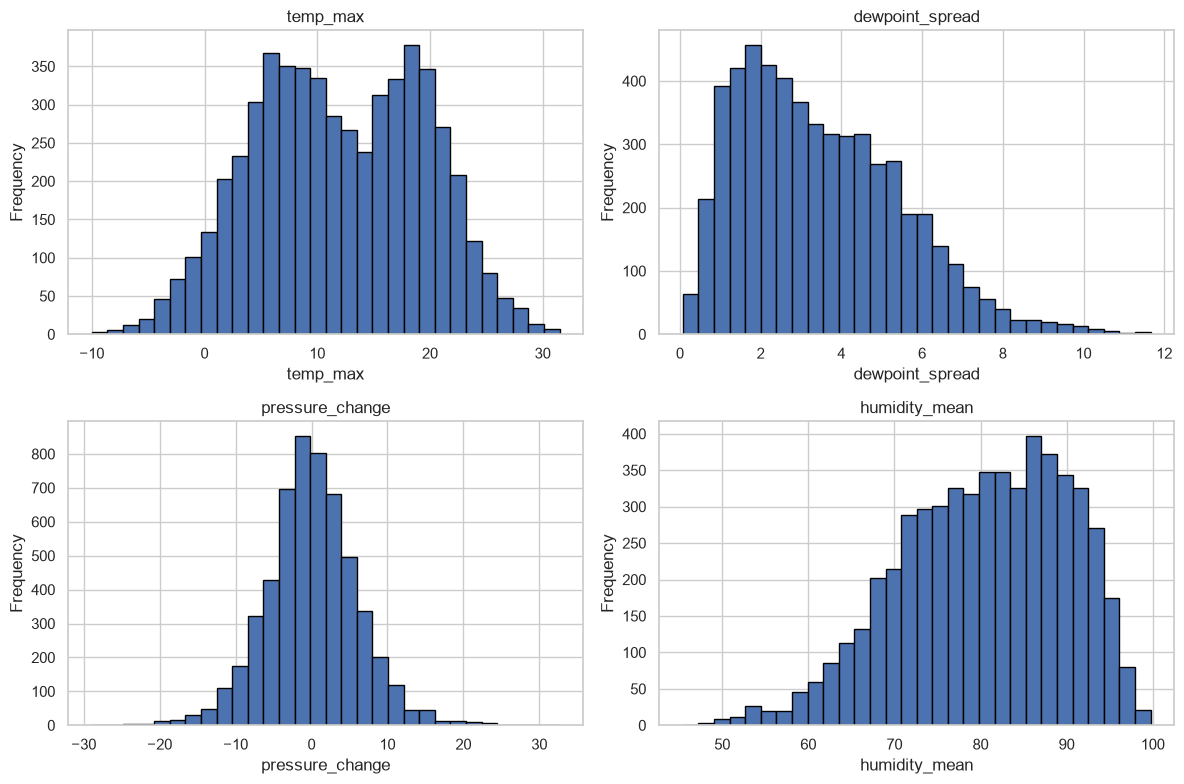

In [8]:
import matplotlib.pyplot as plt

features_to_plot = [
    "temp_max",
    "dewpoint_spread",
    "pressure_change",
    "humidity_mean"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, features_to_plot):
    ax.hist(df_daily[feature], bins=30, edgecolor="black")
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [9]:
# 1. Check distribution skewness
features_to_check = [
    "temp_max",
    "dewpoint_spread",
    "pressure_change",
    "humidity_mean",
    "precipitation_today",
    "wind_speed_max"
]

print("=== Distribution Skewness ===")
print(df_daily[features_to_check].skew().round(2))


# 2. Detect potential outliers using the IQR rule
print("\n=== Potential Outliers (IQR Rule) ===")

for col in features_to_check:
    q1 = df_daily[col].quantile(0.25)
    q3 = df_daily[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df_daily[
        (df_daily[col] < lower) |
        (df_daily[col] > upper)
    ]

    print(
        f"{col}: {len(outliers)} potential outliers "
        f"({len(outliers) / len(df_daily) * 100:.2f}%)"
    )


# 3. Explore the relationship between pressure and humidity
print("\n=== Pressure-Humidity Correlation ===")

print(
    "Pearson correlation:",
    round(df_daily["pressure_mean"].corr(
        df_daily["humidity_mean"], method="pearson"
    ), 3)
)

print(
    "Spearman correlation:",
    round(df_daily["pressure_mean"].corr(
        df_daily["humidity_mean"], method="spearman"
    ), 3)
)

=== Distribution Skewness ===
temp_max              -0.04
dewpoint_spread        0.71
pressure_change        0.06
humidity_mean         -0.43
precipitation_today    3.56
wind_speed_max         0.69
dtype: float64

=== Potential Outliers (IQR Rule) ===
temp_max: 0 potential outliers (0.00%)
dewpoint_spread: 49 potential outliers (0.89%)
pressure_change: 161 potential outliers (2.94%)
humidity_mean: 15 potential outliers (0.27%)
precipitation_today: 550 potential outliers (10.04%)
wind_speed_max: 80 potential outliers (1.46%)

=== Pressure-Humidity Correlation ===
Pearson correlation: -0.229
Spearman correlation: -0.218


In [10]:
#K-means clustering

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
from sklearn.decomposition import PCA

# 1. Select features for clustering
cluster_features = [
    "temp_mean",
    "temp_range",
    "humidity_mean",
    "dewpoint_spread",
    "pressure_mean",
    "pressure_change",
    "cloud_cover_mean",
    "wind_speed_max"
]

X_cluster = df_daily[cluster_features].copy()

# 2. Standardize features
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

# 3. Compare different numbers of clusters
results = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster_scaled)

    silhouette = silhouette_score(
        X_cluster_scaled,
        labels
    )

    results.append({
        "k": k,
        "inertia": round(kmeans.inertia_, 2),
        "silhouette_score": round(silhouette, 4)
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 k  inertia  silhouette_score
 2 31346.07            0.2520
 3 27190.27            0.2026
 4 24494.76            0.1713
 5 22622.90            0.1688
 6 21138.02            0.1613
 7 20141.32            0.1584
 8 19274.40            0.1431


=== Cluster Sizes ===
weather_cluster
0    2404
1    3074
Name: count, dtype: int64

=== Cluster Profiles ===
                 temp_mean  temp_range  humidity_mean  dewpoint_spread  \
weather_cluster                                                          
0                    12.43        8.04          72.18             5.21   
1                     6.31        4.37          86.78             2.13   

                 pressure_mean  pressure_change  cloud_cover_mean  \
weather_cluster                                                     
0                      1010.85             1.21             48.44   
1                      1004.29            -0.94             82.14   

                 wind_speed_max  precipitation_today  rain_tomorrow_rate  
weather_cluster                                                           
0                         20.44                 0.74                0.45  
1                         23.76                 3.01                0.64  

Explained varia

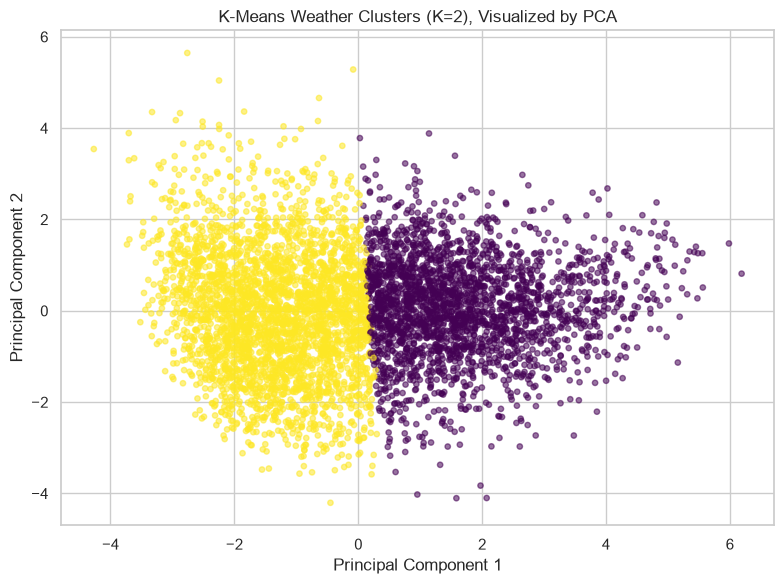

In [12]:
# 1. Fit K-Means with K=2
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_cluster_scaled)

# Store labels for analysis only; do not overwrite the CSV
df_daily["weather_cluster"] = cluster_labels

# 2. Print cluster sizes
print("=== Cluster Sizes ===")
print(
    df_daily["weather_cluster"]
    .value_counts()
    .sort_index()
)

# 3. Compare meteorological characteristics in original units
print("\n=== Cluster Profiles ===")

cluster_profile = df_daily.groupby("weather_cluster").agg(
    temp_mean=("temp_mean", "mean"),
    temp_range=("temp_range", "mean"),
    humidity_mean=("humidity_mean", "mean"),
    dewpoint_spread=("dewpoint_spread", "mean"),
    pressure_mean=("pressure_mean", "mean"),
    pressure_change=("pressure_change", "mean"),
    cloud_cover_mean=("cloud_cover_mean", "mean"),
    wind_speed_max=("wind_speed_max", "mean"),
    precipitation_today=("precipitation_today", "mean"),
    rain_tomorrow_rate=("rain_tomorrow", "mean")
).round(2)

print(cluster_profile)

# 4. PCA: reduce the standardized features to two dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_cluster_scaled)

print("\nExplained variance ratio:",
      pca.explained_variance_ratio_.round(4))
print("Total variance explained:",
      round(pca.explained_variance_ratio_.sum(), 4))

# 5. Plot the clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap="viridis",
    alpha=0.55,
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Weather Clusters (K=2), Visualized by PCA")
plt.tight_layout()
plt.show()

In [13]:
# ==============================================================================
# 5. Supervised Learning - Dataset Splitting
# ==============================================================================

import pandas as pd

# 1. Copy the existing dataset and ensure chronological order
df_model = df_daily.copy()

df_model["date"] = pd.to_datetime(df_model["date"])
df_model = (
    df_model.sort_values("date")
    .reset_index(drop=True)
)

# 2. Select today's weather features
feature_cols = [
    "temp_max",
    "temp_min",
    "temp_mean",
    "humidity_mean",
    "dewpoint_mean",
    "pressure_mean",
    "cloud_cover_mean",
    "wind_speed_max",
    "precipitation_today",
    "temp_range",
    "dewpoint_spread",
    "pressure_change",
    "month"
]

X = df_model[feature_cols]
y = df_model["rain_tomorrow"].astype(int)

# 3. Split chronologically: 70% / 15% / 15%
n = len(df_model)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train = X.iloc[:train_end]
y_train = y.iloc[:train_end]

X_val = X.iloc[train_end:val_end]
y_val = y.iloc[train_end:val_end]

X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

# 4. Print date ranges and dataset sizes
print("=== Dataset Split ===")

for name, start, end, X_part, y_part in [
    ("Training", 0, train_end, X_train, y_train),
    ("Validation", train_end, val_end, X_val, y_val),
    ("Test", val_end, n, X_test, y_test)
]:
    print(f"\n{name} Set")
    print("Number of samples:", len(X_part))
    print(
        "Date range:",
        df_model["date"].iloc[start].date(),
        "to",
        df_model["date"].iloc[end - 1].date()
    )
    print("RainTomorrow proportions:")
    print(y_part.value_counts(normalize=True).sort_index().round(3))

=== Dataset Split ===

Training Set
Number of samples: 3834
Date range: 2010-01-01 to 2020-06-30
RainTomorrow proportions:
rain_tomorrow
0    0.456
1    0.544
Name: proportion, dtype: float64

Validation Set
Number of samples: 822
Date range: 2020-07-01 to 2022-09-30
RainTomorrow proportions:
rain_tomorrow
0    0.426
1    0.574
Name: proportion, dtype: float64

Test Set
Number of samples: 822
Date range: 2022-10-01 to 2024-12-30
RainTomorrow proportions:
rain_tomorrow
0    0.4
1    0.6
Name: proportion, dtype: float64


In [14]:
# ==============================================================================
# 6. Random Forest Classification - Baseline Model
# ==============================================================================

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


# 1. Majority-class baseline
baseline_class = y_train.mode().iloc[0]

baseline_pred = np.full(
    len(y_val),
    baseline_class
)

print("=== Majority-Class Baseline ===")
print("Predicted class:", baseline_class)
print("Validation Accuracy:",
      round(accuracy_score(y_val, baseline_pred), 4))


# ==============================================================================
# 7. Train Random Forest
# ==============================================================================

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Fit the model using the training set only
rf.fit(X_train, y_train)

# Predictions on the validation set
y_val_pred = rf.predict(X_val)
y_val_prob = rf.predict_proba(X_val)[:, 1]


# ==============================================================================
# 8. Validation Evaluation
# ==============================================================================

print("\n=== Random Forest Validation Results ===")

print("Accuracy:",
      round(accuracy_score(y_val, y_val_pred), 4))

print("Precision:",
      round(precision_score(
          y_val, y_val_pred, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_val, y_val_pred, zero_division=0
      ), 4))

print("F1-score:",
      round(f1_score(
          y_val, y_val_pred, zero_division=0
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_val, y_val_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["No Rain", "Rain Tomorrow"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

=== Majority-Class Baseline ===
Predicted class: 1
Validation Accuracy: 0.5742

=== Random Forest Validation Results ===
Accuracy: 0.7092
Precision: 0.7344
Recall: 0.7733
F1-score: 0.7534
ROC-AUC: 0.7649

Classification Report:
               precision    recall  f1-score   support

      No Rain       0.67      0.62      0.65       350
Rain Tomorrow       0.73      0.77      0.75       472

     accuracy                           0.71       822
    macro avg       0.70      0.70      0.70       822
 weighted avg       0.71      0.71      0.71       822

Confusion Matrix:
[[218 132]
 [107 365]]


=== Random Forest Feature Importance ===
            feature  importance
      pressure_mean      0.1463
precipitation_today      0.1221
   cloud_cover_mean      0.1007
    pressure_change      0.0813
     wind_speed_max      0.0790
      dewpoint_mean      0.0661
         temp_range      0.0655
    dewpoint_spread      0.0640
      humidity_mean      0.0638
          temp_mean      0.0615
           temp_min      0.0601
           temp_max      0.0587
              month      0.0308


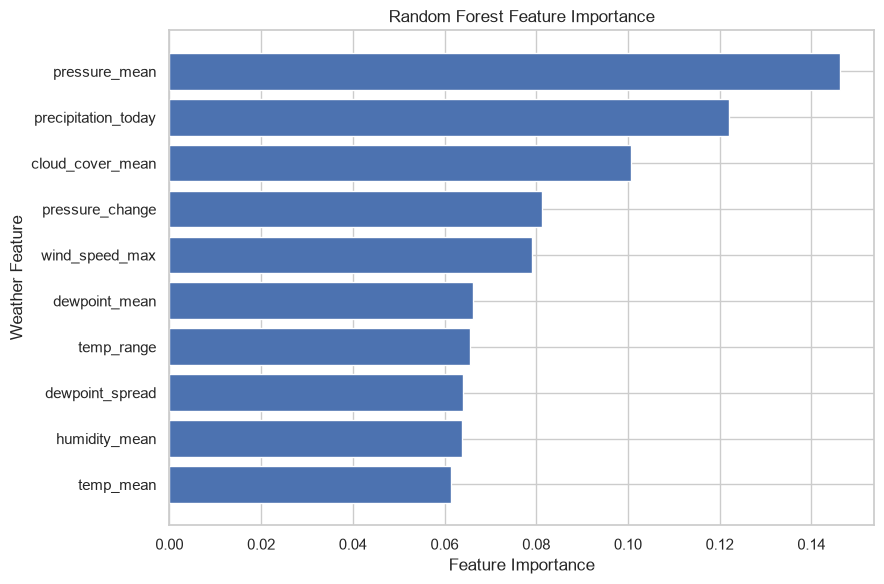

In [15]:
# ==============================================================================
# 9. Feature Importance - Random Forest Built-in Method
# ==============================================================================

# Extract feature importance from the trained Random Forest
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="importance",
    ascending=False
)

print("=== Random Forest Feature Importance ===")
print(importance_df.round(4).to_string(index=False))

# Plot the top 10 features
top10 = importance_df.head(10).sort_values(
    by="importance",
    ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(
    top10["feature"],
    top10["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Weather Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

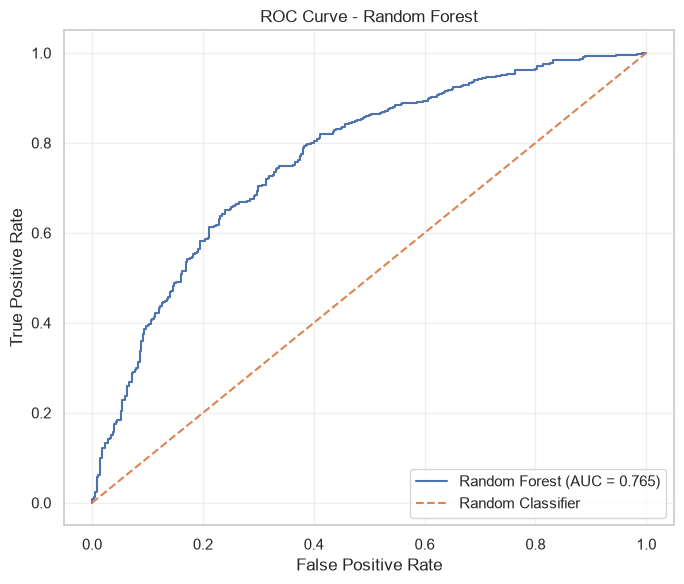

Validation ROC-AUC: 0.7649


In [16]:
# ==============================================================================
# 10. ROC Curve - Random Forest Validation
# ==============================================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_prob)

# Calculate AUC
roc_auc = roc_auc_score(y_val, y_val_prob)

# Plot
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

# Reference line for random guessing
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Validation ROC-AUC: {roc_auc:.4f}")

In [17]:
# ==============================================================================
# 11. Random Forest Hyperparameter Comparison
# ==============================================================================

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Compare a small number of parameter settings
configs = [
    {
        "name": "Current baseline",
        "max_depth": None,
        "min_samples_leaf": 2
    },
    {
        "name": "Shallower trees",
        "max_depth": 10,
        "min_samples_leaf": 2
    },
    {
        "name": "More regularization",
        "max_depth": None,
        "min_samples_leaf": 5
    },
    {
        "name": "Moderate depth",
        "max_depth": 15,
        "min_samples_leaf": 5
    }
]

results = []

for config in configs:
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=config["max_depth"],
        min_samples_leaf=config["min_samples_leaf"],
        random_state=42,
        n_jobs=-1
    )

    # Train using the training set only
    model.fit(X_train, y_train)

    # Evaluate using the validation set
    pred = model.predict(X_val)
    prob = model.predict_proba(X_val)[:, 1]

    results.append({
        "model": config["name"],
        "accuracy": accuracy_score(y_val, pred),
        "precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_val, pred, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_val, prob)
    })

results_df = pd.DataFrame(results)

print("=== Validation Results: Parameter Comparison ===")
print(
    results_df.round(4)
    .sort_values("f1_score", ascending=False)
    .to_string(index=False)
)

=== Validation Results: Parameter Comparison ===
              model  accuracy  precision  recall  f1_score  roc_auc
     Moderate depth    0.7226     0.7421  0.7924    0.7664   0.7702
More regularization    0.7214     0.7416  0.7903    0.7651   0.7686
    Shallower trees    0.7141     0.7337  0.7881    0.7600   0.7712
   Current baseline    0.7092     0.7344  0.7733    0.7534   0.7649


hypeparameter chosen(moderate depth):

n_estimators=300
max_depth=15
min_samples_leaf=5

In [18]:
#Model testing 

In [19]:
# ==============================================================================
# Final Model: Train on Training + Validation Sets
# ==============================================================================

import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Combine training and validation sets
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

# 2. Train the final Random Forest
final_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

final_rf.fit(X_train_val, y_train_val)

# 3. Predict on the untouched test set
y_test_pred = final_rf.predict(X_test)
y_test_prob = final_rf.predict_proba(X_test)[:, 1]

# 4. Evaluate final model
print("=== Final Random Forest: Test Results ===")

print("Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("Precision:",
      round(precision_score(
          y_test, y_test_pred, zero_division=0
      ), 4))

print("Recall:",
      round(recall_score(
          y_test, y_test_pred, zero_division=0
      ), 4))

print("F1-score:",
      round(f1_score(
          y_test, y_test_pred, zero_division=0
      ), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_test_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["No Rain", "Rain Tomorrow"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred, labels=[0, 1]))

# 5. Compare with majority-class baseline on the test set
baseline_class = y_train_val.mode().iloc[0]
baseline_pred = [baseline_class] * len(y_test)

print("\nMajority-Class Baseline Accuracy:",
      round(accuracy_score(y_test, baseline_pred), 4))

=== Final Random Forest: Test Results ===
Accuracy: 0.7518
Precision: 0.7752
Recall: 0.8256
F1-score: 0.7996
ROC-AUC: 0.7857

Classification Report:
               precision    recall  f1-score   support

      No Rain       0.71      0.64      0.67       329
Rain Tomorrow       0.78      0.83      0.80       493

     accuracy                           0.75       822
    macro avg       0.74      0.73      0.74       822
 weighted avg       0.75      0.75      0.75       822

Confusion Matrix:
[[211 118]
 [ 86 407]]

Majority-Class Baseline Accuracy: 0.5998


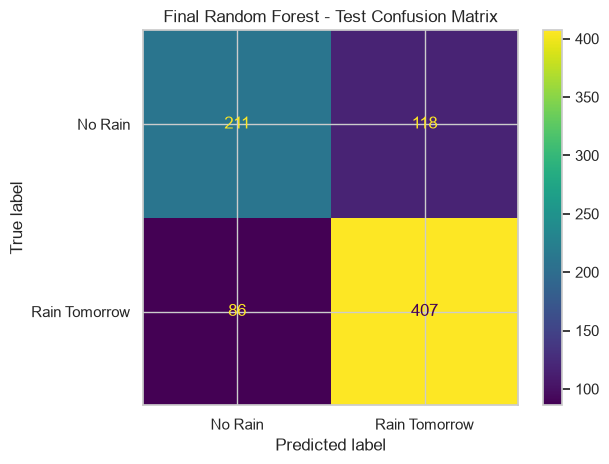

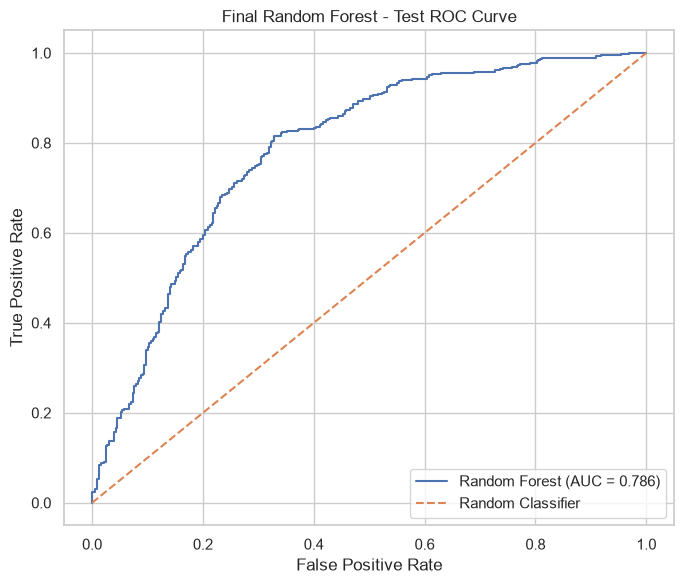

=== Final Model Feature Importance ===
            feature  importance
      pressure_mean      0.1727
precipitation_today      0.1531
   cloud_cover_mean      0.1150
    pressure_change      0.0738
     wind_speed_max      0.0702
         temp_range      0.0605
      dewpoint_mean      0.0590
      humidity_mean      0.0566
    dewpoint_spread      0.0557
           temp_min      0.0542
          temp_mean      0.0538
           temp_max      0.0485
              month      0.0269


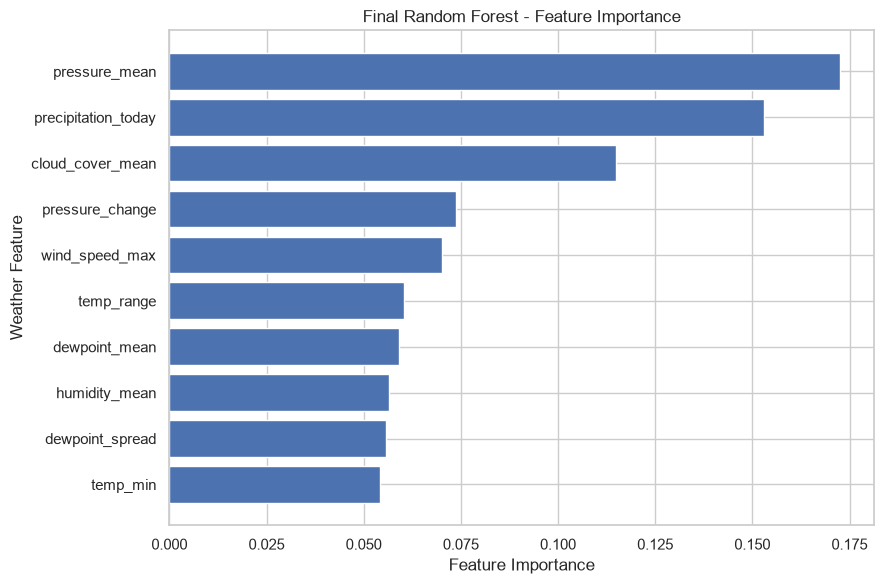


Final Test ROC-AUC: 0.7857


In [20]:
# ==============================================================================
# Final Model Visualization
# ==============================================================================


from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=[0, 1],
    display_labels=["No Rain", "Rain Tomorrow"],
    values_format="d"
)

plt.title("Final Random Forest - Test Confusion Matrix")
plt.tight_layout()
plt.savefig("test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


# 2. ROC Curve on the Test Set
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)
test_auc = roc_auc_score(y_test, y_test_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {test_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Random Forest - Test ROC Curve")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("test_roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()


# 3. Feature Importance of the Final Model
importance_df = pd.DataFrame({
    "feature": X_train_val.columns,
    "importance": final_rf.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print("=== Final Model Feature Importance ===")
print(importance_df.round(4).to_string(index=False))

top10 = importance_df.head(10).sort_values("importance")

plt.figure(figsize=(9, 6))
plt.barh(top10["feature"], top10["importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Weather Feature")
plt.title("Final Random Forest - Feature Importance")
plt.tight_layout()
plt.savefig("test_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"\nFinal Test ROC-AUC: {test_auc:.4f}")